<a href="https://colab.research.google.com/github/EnesKok20/cepte-vet/blob/main/notebooks/02_ikinci_veri_seti.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - İkinci Veri Seti: Zenodo (LumpySkinDisease_DataHub)

Bu defterde Zenodo'daki LumpySkinDisease_DataHub veri setini inceliyorum.
Amacım, görüntülerin sayısını ve kalitesini görmek ve daha sonra
Mendeley setiyle aynı görüntüler olup olmadığını kontrol etmek.

- Kaynak: https://zenodo.org/records/11003967
- Lisans: CC BY 4.0
- Zip dosyası (488 MB) bir kere indirildi ve Drive'daki `raw` klasörüne kaydedildi.
  Bu defter dosyayı oradan kullanıyor, tekrar indirmiyor.

In [23]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, random
import matplotlib.pyplot as plt
from PIL import Image

RAW = '/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw'
VERI = '/content/data/zenodo'
UZANTILAR = ('.png', '.jpg', '.jpeg', '.webp', '.bmp')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Dış zip'i açma

Zip'in içinde yazarların kodları ve veri klasörü var. Zip Mac'te hazırlandığı
için içindeki `__MACOSX` ve `.DS_Store` gibi gereksiz dosyaları atlıyorum.

In [24]:
!mkdir -p {VERI}
!unzip -q -o "{RAW}/LumpySkinDisease_DataHub.zip" -d {VERI} -x "__MACOSX/*" "*.DS_Store"
!find {VERI} -maxdepth 3 -name "*.zip"

[/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw/LumpySkinDisease_DataHub.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw/LumpySkinDisease_DataHub.zip or
        /content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw/LumpySkinDisease_DataHub.zip.zip, and cannot find /content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/raw/LumpySkinDisease_DataHub.zip.ZIP, period.
/content/data/zenodo/LumpySkinDisease_DataHub/data-processed/lumpy_unbalanced.zip
/content/data/zenodo/LumpySkinDisease_DataHub/data-processed/lumpy_balanced.zip


## 2. İçteki veri zip'ini açma

Veri setinde dengeli (`balanced`) ve dengesiz (`unbalanced`) iki sürüm var.
Dengeli sürüm yaklaşık iki kat büyük; az olan sınıfın augmentation ile
çoğaltıldığını düşündürüyor. Çoğaltılmış kopyalar eğitim ve test setlerine
dağılırsa sonuçlar yanıltıcı olabileceği için orijinal görüntüleri içeren
dengesiz sürümü kullanıyorum.

In [25]:
ic_zip = glob.glob(f'{VERI}/**/lumpy_unbalanced.zip', recursive=True)[0]
print('Açılıyor:', ic_zip)
!unzip -q -o "{ic_zip}" -d {VERI}/unbalanced -x "__MACOSX/*" "*.DS_Store"

Açılıyor: /content/data/zenodo/LumpySkinDisease_DataHub/data-processed/lumpy_unbalanced.zip
caution: excluded filename not matched:  __MACOSX/*
caution: excluded filename not matched:  *.DS_Store


## 3. Sınıflara göre görüntü sayısı

In [26]:
siniflar = {}
for klasor, alt_klasorler, dosyalar in os.walk(f'{VERI}/unbalanced'):
    resimler = [os.path.join(klasor, d) for d in dosyalar if d.lower().endswith(UZANTILAR)]
    if resimler:
        siniflar[klasor] = resimler
        print(f'{klasor.replace(VERI, "")} -> {len(resimler)} görüntü')

/unbalanced/lumpy -> 1019 görüntü


## 4. Klasör yapısı ve etiketlerin kontrolü

İlk denemede tek bir `lumpy` klasörü çıktı ve içinde sağlıklı görünen
hayvanlar vardı. Etiketlerin dosya adlarında ya da ayrı bir tabloda
tutulup tutulmadığını kontrol ediyorum.

In [27]:
!find {VERI}/unbalanced -maxdepth 3 -type d
print('-----')
!find {VERI}/unbalanced -type f ! -iname "*.png" ! -iname "*.jpg" ! -iname "*.jpeg" | head -10
print('-----')
ornek = list(siniflar.values())[0]
for yol in random.sample(ornek, 10):
    print(os.path.basename(yol))

/content/data/zenodo/unbalanced
/content/data/zenodo/unbalanced/lumpy
-----
-----
Mild_198.png
Normal_Skin_629.png
Normal_Skin_258.png
Mild_182.png
Normal_Skin_117.png
Normal_Skin_365.png
Mild_64.png
Mild_62.png
Mild_200.png
Normal_Skin_190.png


## 5. Örnek görüntüler

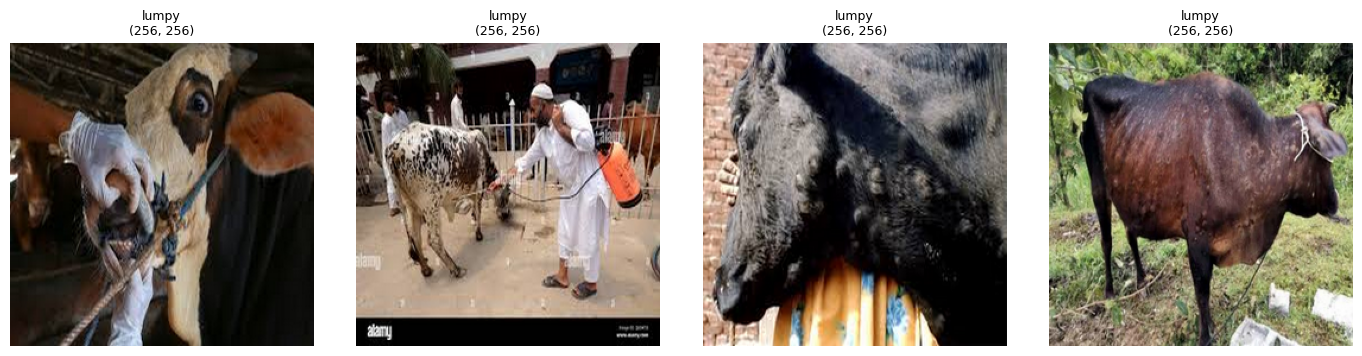

In [28]:
fig, eksenler = plt.subplots(len(siniflar), 4, figsize=(14, 3.5 * len(siniflar)), squeeze=False)
for satir, (klasor, resimler) in enumerate(siniflar.items()):
    ad = os.path.basename(klasor)
    for sutun, yol in enumerate(random.sample(resimler, min(4, len(resimler)))):
        resim = Image.open(yol)
        eksenler[satir, sutun].imshow(resim)
        eksenler[satir, sutun].set_title(f'{ad}\n{resim.size}', fontsize=9)
        eksenler[satir, sutun].axis('off')
plt.tight_layout()
plt.show()

## 4b. Dosya adlarından sınıfları çıkarma

Bu veri setinde etiketler klasörlerde değil dosya adlarında tutuluyor
(ör. `Mild_198.png`, `Normal_Skin_629.png`). Dosya adının sondaki numara
hariç kısmını sınıf adı olarak alıp her sınıfı sayıyorum.

In [29]:
from collections import Counter

tum_resimler = [y for liste in siniflar.values() for y in liste]

def sinif_adi(yol):
    ad = os.path.splitext(os.path.basename(yol))[0]   # 'Mild_198'
    return ad.rsplit('_', 1)[0]                       # 'Mild'

sayim = Counter(sinif_adi(y) for y in tum_resimler)
for sinif, adet in sayim.most_common():
    print(f'{sinif}: {adet}')
print('Toplam:', sum(sayim.values()))

Normal_Skin: 696
Mild: 231
Severe: 91
Normal: 1
Toplam: 1019


In [30]:
for y in tum_resimler:
    if sinif_adi(y) == 'Normal':
        print(os.path.basename(y))

Normal_Skin.png


## 5b. Gerçek etiketlere göre örnek görüntüler

Yukarıdaki 5. bölümde başlıklara klasör adını yazdırdığım için tüm görüntüler
"lumpy" görünüyordu. Oysa etiketler dosya adlarında tutuluyor. Burada
görüntüleri dosya adlarından çıkardığım gerçek sınıflara göre gösteriyorum:
Normal_Skin (sağlıklı), Mild (hafif) ve Severe (şiddetli).

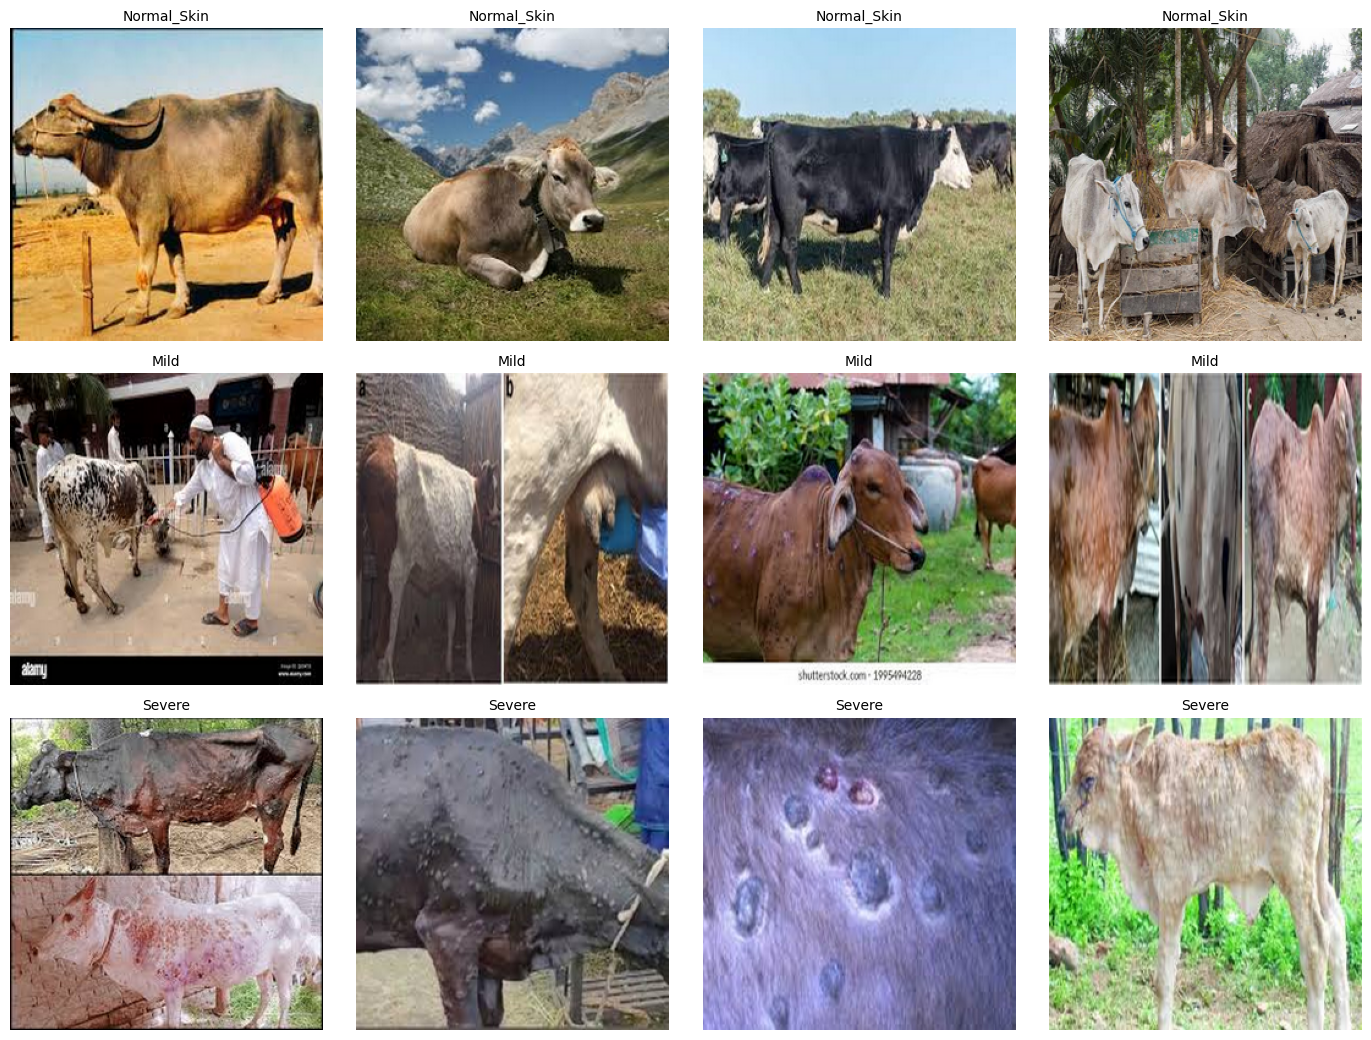

In [31]:
gruplar = {}
for y in tum_resimler:
    gruplar.setdefault(sinif_adi(y), []).append(y)

goster = ['Normal_Skin', 'Mild', 'Severe']
fig, eksenler = plt.subplots(len(goster), 4, figsize=(14, 3.5 * len(goster)), squeeze=False)
for satir, ad in enumerate(goster):
    for sutun, yol in enumerate(random.sample(gruplar[ad], 4)):
        eksenler[satir, sutun].imshow(Image.open(yol))
        eksenler[satir, sutun].set_title(ad, fontsize=10)
        eksenler[satir, sutun].axis('off')
plt.tight_layout()
plt.show()

## 6. Gözlemlerim

1. Etiketler klasörlerde değil dosya adlarında tutuluyor. Tüm görüntüler tek
   bir `lumpy` klasöründe. Bunu ilk denemede "lumpy" başlıklı sağlıklı hayvan
   görüntüleri görünce fark ettim.
2. Sınıf dağılımı: Normal_Skin 696, Mild 231, Severe 91 ve adı hatalı yazılmış
   1 Normal dosyası. Toplam 1.019 görüntü.
3. Sayılar Mendeley setine çok yakın (Mendeley: 700 normal, 324 lumpy, toplam
   1.024). Görüntü boyutları da aynı (256x256). Bu set büyük ihtimalle
   Mendeley görüntülerinin hastalık şiddetine göre yeniden etiketlenmiş hali.
   Bunu hash karşılaştırmasıyla kontrol edeceğim.
4. Yeni görüntü katmasa bile hastalık şiddeti etiketi (Mild / Severe) değerli
   bir bilgi. Şimdilik ikili sınıflandırma yapacağım (Mild + Severe = lumpy),
   ileride şiddet sınıflandırması için bu etiketleri kullanabilirim.
5. Bazı görüntülerde stok fotoğraf filigranı (alamy) var; internetten
   toplanmış görüntüler içeriyor.